### Importing libraries

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

### Importing data

In [3]:
items_processed = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/items_data_processed/high_conf_items_processed_day.csv", sep=";", low_memory=False)
currency_processed = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/currency_data_processed/currency_processed.csv", sep=";", low_memory=False)
basket=pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/items_data_processed/basket.csv", sep=";", low_memory=False)

In [5]:
items_processed

,League,Date,Type,Name,Value,Confidence,Day
0,Keepers,2025-10-31,UniqueWeapon,Redbeak,0.935,High,1
1,Keepers,2025-11-01,UniqueWeapon,Redbeak,0.300,High,2
2,Keepers,2025-11-02,UniqueWeapon,Redbeak,0.120,High,3
3,Keepers,2025-11-03,UniqueWeapon,Redbeak,0.180,High,4
4,Keepers,2025-11-04,UniqueWeapon,Redbeak,1.000,High,5
...,...,...,...,...,...,...,...
17311734,Ancestor,2023-11-05,UniqueWeapon,The First Crest,11.000,High,80
17311735,Ancestor,2023-10-20,UniqueWeapon,The Original Scripture,29808.690,Medium,64
17311736,Ancestor,2023-10-21,UniqueWeapon,The Original Scripture,29212.610,Medium,65
17311737,Ancestor,2023-10-22,UniqueWeapon,The Original Scripture,29122.535,Medium,66


In [6]:
currency_processed

,League,Date,Get,Pay,Value,Confidence
0,Keepers,2025-10-31,Chromatic Orb,Chaos Orb,0.20000,High
1,Keepers,2025-11-01,Chromatic Orb,Chaos Orb,0.19231,High
2,Keepers,2025-11-02,Chromatic Orb,Chaos Orb,0.19231,High
3,Keepers,2025-11-03,Chromatic Orb,Chaos Orb,0.16667,High
4,Keepers,2025-11-04,Chromatic Orb,Chaos Orb,0.14970,High
...,...,...,...,...,...,...
169653,Ancestor,2023-12-01,Kirac's Memory,Chaos Orb,10.00000,High
169654,Ancestor,2023-12-02,Kirac's Memory,Chaos Orb,10.00000,High
169655,Ancestor,2023-12-03,Kirac's Memory,Chaos Orb,10.00000,High
169656,Ancestor,2023-12-04,Kirac's Memory,Chaos Orb,10.00000,High


In [7]:
basket

,Name,Type
0,Aegis Aurora,UniqueArmour
1,Amanamu's Gaze,UniqueJewel
2,Anathema,UniqueAccessory
3,Ashes of the Stars,UniqueAccessory
4,Aul's Uprising,UniqueAccessory
5,Awakened Multistrike Support,SkillGem
6,Darkness Enthroned,UniqueAccessory
7,Dying Sun,UniqueFlask
8,Heatshiver,UniqueArmour
9,Headhunter,UniqueAccessory


# Currency Purchasing Power Index 
based on real life CPI: Consumer Price Index

In [66]:
# Adjusting basket dataframe
basket_items = basket["Name"]

basket_prices = items_processed[items_processed["Name"].isin(basket_items)].copy()
basket_prices = basket_prices[["League", "Day", "Name", "Value"]]

basket_prices = basket_prices.rename(columns={"Value": "price_chaos"})
basket_prices

,League,Day,Name,price_chaos
41693,Keepers,1,Heatshiver,10.00
41694,Keepers,2,Heatshiver,27.00
41695,Keepers,3,Heatshiver,11.00
41696,Keepers,4,Heatshiver,7.00
41697,Keepers,5,Heatshiver,8.00
...,...,...,...,...
17261095,Ancestor,37,Starforge,2337.45
17261096,Ancestor,38,Starforge,1778.25
17261097,Ancestor,39,Starforge,933.92
17261098,Ancestor,40,Starforge,910.07


In [70]:
# Price of the entire basket per day and league
basket_price_per_day = (basket_prices.groupby(["League", "Day"])["price_chaos"].sum().reset_index())
basket_price_per_day = basket_price_per_day.rename(columns={"price_chaos": "basket_price"})
basket_price_per_day

,League,Day,basket_price
0,Affliction,1,372.100
1,Affliction,2,2978.970
2,Affliction,3,10296.970
3,Affliction,4,60980.920
4,Affliction,5,73598.155
...,...,...,...
911,Settlers,315,611571.210
912,Settlers,316,594654.730
913,Settlers,317,496280.140
914,Settlers,318,486354.540


In [71]:
# Normalisation realtive to the first day of the league

# price of basket on day 1

day1_prices = (basket_price_per_day[basket_price_per_day["Day"] == 1][["League","basket_price"]].rename(columns={"basket_price":"basket_price_day1"}))
basket_price_per_day = basket_price_per_day.merge(day1_prices,on="League",how="left").copy()

# currency index
basket_price_per_day["currency_index"] = (basket_price_per_day["basket_price"] /basket_price_per_day["basket_price_day1"])
basket_price_per_day = basket_price_per_day[basket_price_per_day["Day"] <= 110].copy()
basket_price_per_day

,League,Day,basket_price,basket_price_day1,currency_index
0,Affliction,1,372.100,372.10,1.000000
1,Affliction,2,2978.970,372.10,8.005832
2,Affliction,3,10296.970,372.10,27.672588
3,Affliction,4,60980.920,372.10,163.883150
4,Affliction,5,73598.155,372.10,197.791333
...,...,...,...,...,...
702,Settlers,106,454477.920,296.16,1534.568882
703,Settlers,107,524225.300,296.16,1770.074622
704,Settlers,108,543615.775,296.16,1835.547593
705,Settlers,109,497425.225,296.16,1679.582742


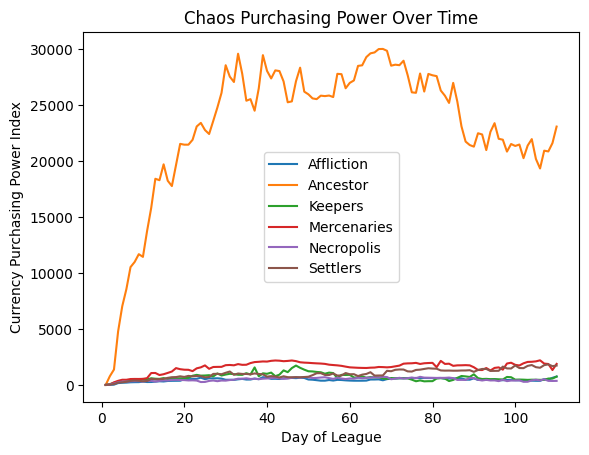

In [72]:
for league, df_league in basket_price_per_day.groupby("League"):
    
    plt.plot(
        df_league["Day"],
        df_league["currency_index"],
        label=league
    )

plt.xlabel("Day of League")
plt.ylabel("Currency Purchasing Power Index")
plt.title("Chaos Purchasing Power Over Time")
plt.legend()

plt.show()